# Свёртки и компьютерное зрение. Деформируемая свёртка

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "04_deformable_convolution"
OUT.mkdir(exist_ok=True, parents=True)

## Ручная свёртка, размеры и baseline

MNIST: 2400 train, 600 validation, 600 test. Вход [B, 1, 28, 28]. Метрики — accuracy и macro-F1. В CNN два свёрточных блока. Размер выхода свёртки: floor((n + 2p − k)/s) + 1.

Ручная операция cross-correlation:
 [[-6. -6. -6.]
 [-6. -6. -6.]
 [-6. -6. -6.]]
Размеры padding=0: torch.Size([1, 1, 3, 3]) padding=1: torch.Size([1, 1, 5, 5])
MLP validation: {'accuracy': 0.91, 'macro_f1': 0.9070925545892236} параметров: 50890


CNN validation: {'accuracy': 0.8983333333333333, 'macro_f1': 0.8949752621921638} параметров: 2698


,layer,output
0,"Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1)...","(2, 8, 28, 28)"
1,ReLU(),"(2, 8, 28, 28)"
2,"MaxPool2d(kernel_size=2, stride=2, padding=0, ...","(2, 8, 14, 14)"
3,"Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1...","(2, 16, 14, 14)"
4,ReLU(),"(2, 16, 14, 14)"
5,"MaxPool2d(kernel_size=2, stride=2, padding=0, ...","(2, 16, 7, 7)"


Первый Conv2d, вручную: 80


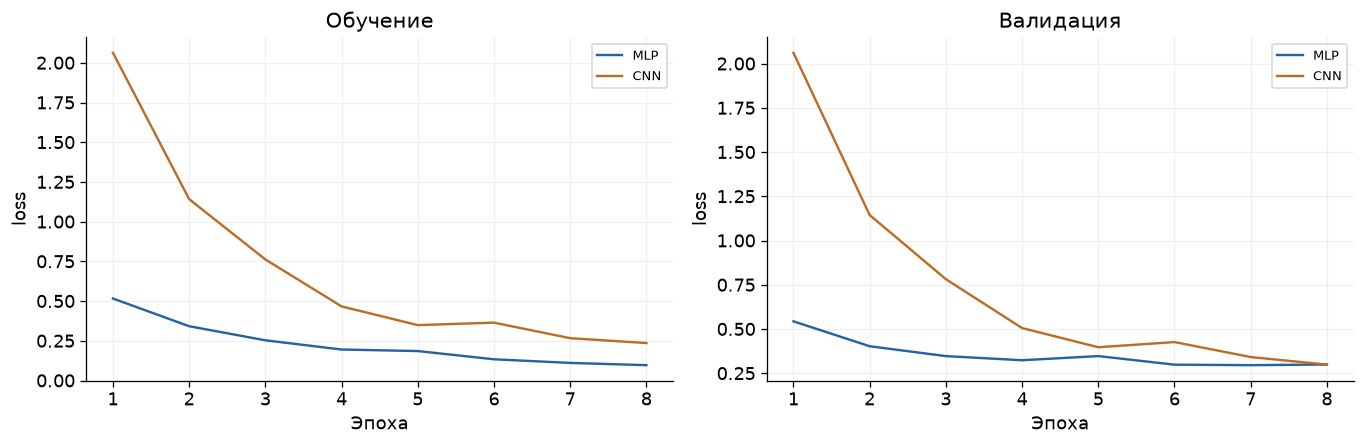

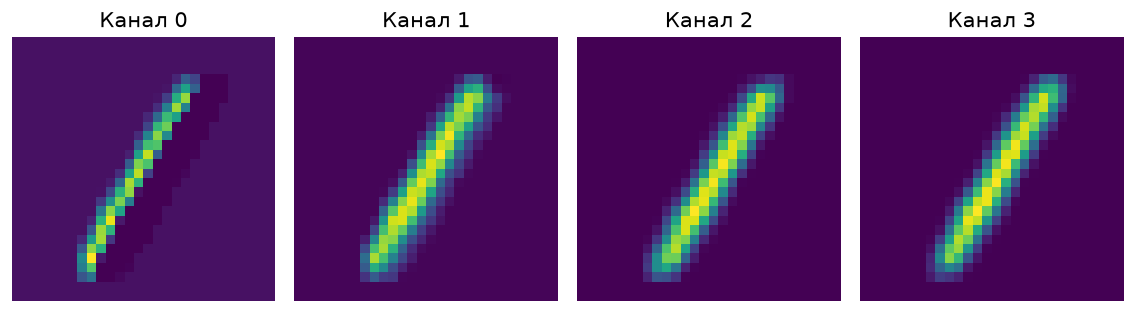

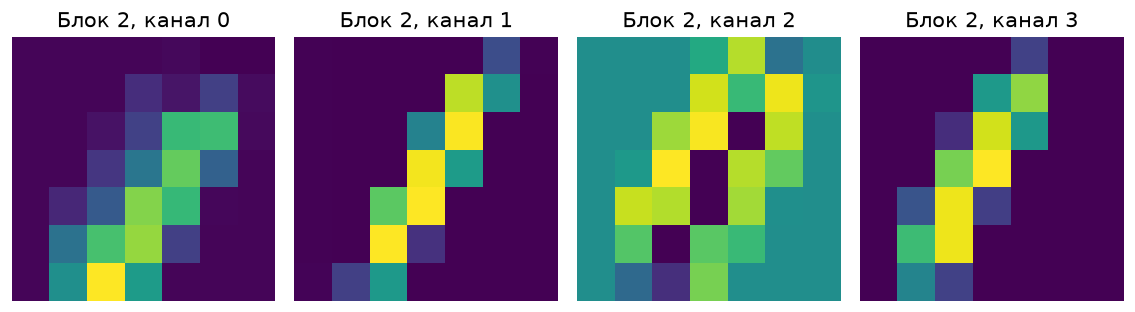

Ранние карты реагируют на локальные штрихи и границы; последующие объединяют несколько локальных структур. В PyTorch Conv2d вычисляет cross-correlation, поэтому ручная проверка использует ядро без отражения.

In [2]:
import torch.nn.functional as F
from torchvision.ops import deform_conv2d

train, val, test = mnist()
a = np.arange(25, dtype="float32").reshape(5, 5)
k = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype="float32")
manual = np.array(
    [[np.sum(a[i : i + 3, j : j + 3] * k) for j in range(3)] for i in range(3)]
)
conv = F.conv2d(tensor(a)[None, None], tensor(k)[None, None])
assert np.allclose(manual, conv.numpy()[0, 0])
print("Ручная операция cross-correlation:\n", manual)
print(
    "Размеры padding=0:",
    conv.shape,
    "padding=1:",
    F.conv2d(tensor(a)[None, None], tensor(k)[None, None], padding=1).shape,
)
seed_all()
baseline = MLP(784, 10, (64,))
baseline, bh, bt = fit(baseline, train, val, epochs=8, lr=0.003)
print(
    "MLP validation:", classify(baseline, val)[0], "параметров:", count_params(baseline)
)
seed_all()
cnn = CNN()
cnn, ch, ct = fit(cnn, train, val, epochs=8, lr=0.003)
print("CNN validation:", classify(cnn, val)[0], "параметров:", count_params(cnn))
xb = train[0][:2]
shape_rows = []
for i, layer in enumerate(cnn.features):
    xb = layer(xb)
    shape_rows.append({"layer": str(layer), "output": str(tuple(xb.shape))})
table(shape_rows, OUT, "dimensions")
print("Первый Conv2d, вручную:", 8 * (1 * 3 * 3 + 1))
histories({"MLP": bh, "CNN": ch}, OUT, "baseline_curves")
acts = cnn.features[:2](test[0][:1]).detach().numpy()[0]
fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for i, a in enumerate(ax):
    a.imshow(acts[i], cmap="viridis")
    a.set_title(f"Канал {i}")
    a.axis("off")
showfig("first_feature_maps", OUT)
acts2 = cnn.features(test[0][:1]).detach().numpy()[0]
fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for i, a in enumerate(ax):
    a.imshow(acts2[i], cmap="viridis")
    a.set_title(f"Блок 2, канал {i}")
    a.axis("off")
showfig("second_feature_maps", OUT)
note(
    "Ранние карты реагируют на локальные штрихи и границы; последующие объединяют несколько локальных структур. В PyTorch Conv2d вычисляет cross-correlation, поэтому ручная проверка использует ядро без отражения."
)

## Padding, stride, pooling и устойчивость

Меняю по одному параметру CNN и проверяю качество на чистых и зашумлённых изображениях.

,configuration,accuracy,macro_f1,seconds,parameters
0,standard,0.87000,0.86736,0.99895,2698
1,padding0,0.88167,0.88145,0.88963,2698
2,stride2,0.86500,0.86378,1.15035,2698
3,average_pool,0.80167,0.79431,0.96226,2698


CNN clean: {'accuracy': 0.93, 'macro_f1': 0.9295509289420556} noise σ=.2: {'accuracy': 0.755, 'macro_f1': 0.74963808880458}


,index,true,predicted,confidence,probability_margin,analysis
0,47,4,0,0.47174,0.10827,Ошибка при близких вероятностях классов
1,50,7,2,0.92757,0.87445,Уверенная ошибка: проверить неоднозначность пр...
2,51,9,4,0.47398,0.22991,Ошибка при близких вероятностях классов
3,86,5,9,0.68914,0.43054,Уверенная ошибка: проверить неоднозначность пр...
4,97,8,6,0.56000,0.29709,Уверенная ошибка: проверить неоднозначность пр...
5,98,9,0,0.89628,0.83948,Уверенная ошибка: проверить неоднозначность пр...
6,99,1,6,0.95837,0.94016,Уверенная ошибка: проверить неоднозначность пр...
7,100,7,8,0.30550,0.04342,Ошибка при близких вероятностях классов
8,101,3,2,0.25628,0.00939,Ошибка при близких вероятностях классов
9,104,3,5,0.48464,0.20208,Ошибка при близких вероятностях классов


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

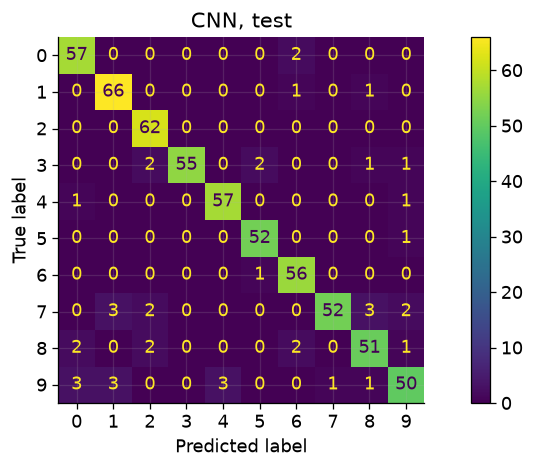

Большой stride и pooling сокращают пространственное разрешение. Это снижает вычислительную нагрузку и может удалить тонкие штрихи. Изменение padding также меняет долю краевых пикселей. Ошибки похожих цифр дополнительно усиливаются шумом.

In [3]:
rows = []
for label, kw in [
    ("standard", {}),
    ("padding0", {"padding": 0}),
    ("stride2", {"stride": 2}),
    ("average_pool", {"pool": "average"}),
]:
    seed_all()
    m = CNN(**kw)
    m, h, t = fit(m, train, val, epochs=5, lr=0.003)
    metrics, _, _ = classify(m, val)
    rows.append(
        {"configuration": label, **metrics, "seconds": t, "parameters": count_params(m)}
    )
table(rows, OUT, "geometry_experiments")
seed_all()
noisy = (torch.clamp(test[0] + 0.2 * torch.randn_like(test[0]), 0, 1), test[1])
print("CNN clean:", classify(cnn, test)[0], "noise σ=.2:", classify(cnn, noisy)[0])
errors(cnn, test, OUT)
metrics, pred, p = classify(cnn, test)
ConfusionMatrixDisplay.from_predictions(test[1], pred)
plt.title("CNN, test")
showfig("confusion", OUT)
note(
    "Большой stride и pooling сокращают пространственное разрешение. Это снижает вычислительную нагрузку и может удалить тонкие штрихи. Изменение padding также меняет долю краевых пикселей. Ошибки похожих цифр дополнительно усиливаются шумом."
)

## Вариант 11. Адаптивная область выборки

В deformable convolution к координатам ядра добавляются обучаемые смещения. Сравниваю обычную свёртку, нулевые и обучаемые смещения на одном разбиении MNIST, затем добавляю шум двух уровней. Использую torchvision.ops.deform_conv2d.

,mode,accuracy,macro_f1,seconds,parameters
0,regular,0.90667,0.90443,1.59739,2698
1,zero,0.90667,0.90427,6.34408,2698
2,learned,0.91833,0.91628,7.06516,2878
3,learned_noise_0.1,0.90667,0.90567,NaN,2878
4,learned_noise_0.3,0.61000,0.59154,NaN,2878


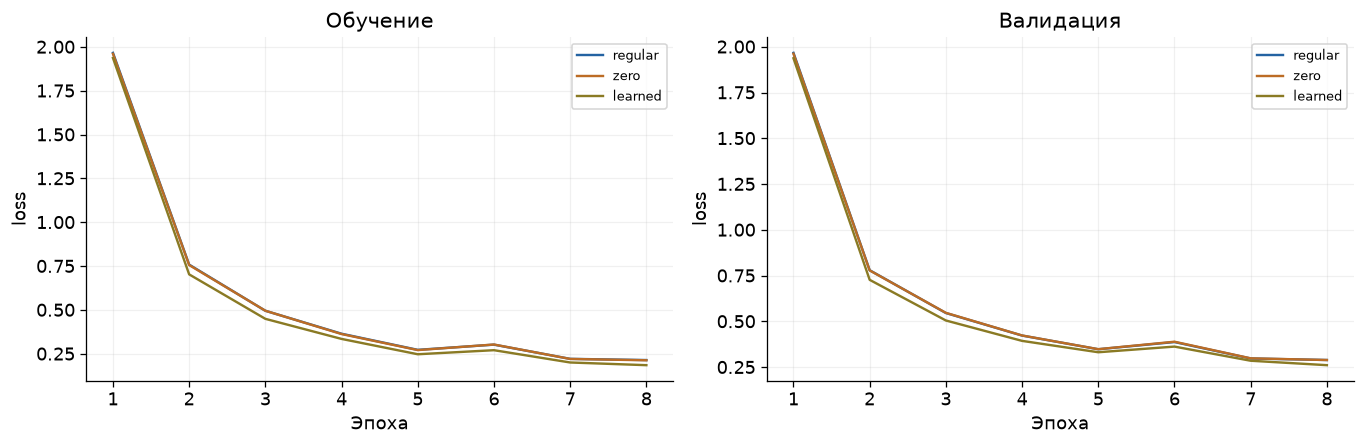

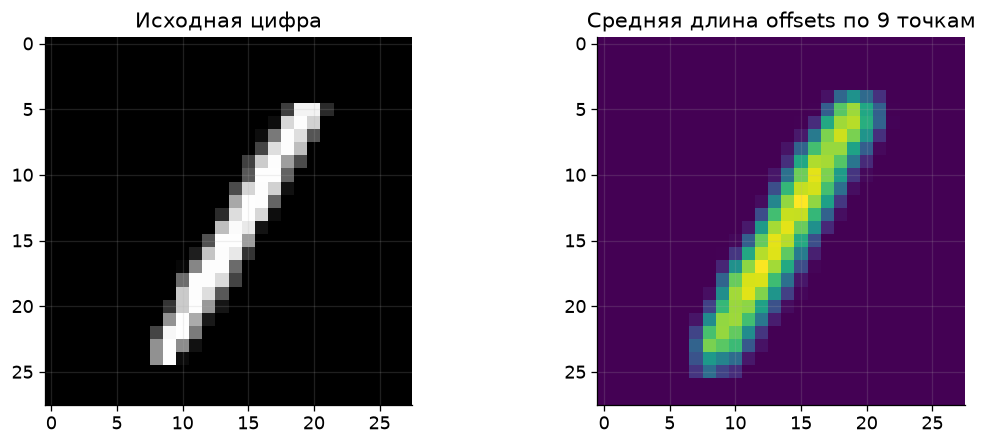

Test learned offsets: {'accuracy': 0.9366666666666666, 'macro_f1': 0.9355679586481482}


,index,true,predicted,confidence,probability_margin,analysis
0,11,5,6,0.55663,0.24516,Ошибка при близких вероятностях классов
1,47,4,6,0.75902,0.61550,Уверенная ошибка: проверить неоднозначность пр...
2,50,7,2,0.96408,0.93185,Уверенная ошибка: проверить неоднозначность пр...
3,86,5,9,0.53906,0.09175,Ошибка при близких вероятностях классов
4,97,8,4,0.67783,0.48917,Уверенная ошибка: проверить неоднозначность пр...
5,98,9,0,0.60190,0.28885,Уверенная ошибка: проверить неоднозначность пр...
6,99,1,6,0.98238,0.97307,Уверенная ошибка: проверить неоднозначность пр...
7,104,3,5,0.58673,0.20177,Ошибка при близких вероятностях классов
8,107,6,5,0.91371,0.88532,Уверенная ошибка: проверить неоднозначность пр...
9,115,9,7,0.48525,0.22606,Ошибка при близких вероятностях классов


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

Нулевые offsets численно воспроизводят обычную свёртку. Обучаемые offsets дают пространственную адаптацию и дополнительные параметры. На небольшом MNIST выигрыш может отсутствовать: маленькая выборка и дополнительная сложность ограничивают пользу. Скорость измерена на CPU; точное преимущество зависит от реализации оператора.

In [4]:
class DeformNet(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        self.weight = nn.Parameter(torch.empty(8, 1, 3, 3))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        self.bias = nn.Parameter(torch.zeros(8))
        self.offset = nn.Conv2d(1, 18, 3, padding=1)
        nn.init.zeros_(self.offset.weight)
        nn.init.zeros_(self.offset.bias)
        if mode != "learned":
            self.offset.requires_grad_(False)
        self.tail = nn.Sequential(
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((3, 3)),
            nn.Flatten(),
            nn.Linear(144, 10),
        )

    def forward(self, x):
        if self.mode == "regular":
            z = F.conv2d(x, self.weight, self.bias, padding=1)
        else:
            offset = (
                self.offset(x)
                if self.mode == "learned"
                else torch.zeros(x.shape[0], 18, x.shape[2], x.shape[3])
            )
            z = deform_conv2d(x, offset, self.weight, self.bias, padding=(1, 1))
        return self.tail(z)


seed_all()
zero = DeformNet("zero")
regular = DeformNet("regular")
regular.load_state_dict(zero.state_dict())
assert torch.allclose(zero(test[0][:2]), regular(test[0][:2]), atol=1e-5)
rows = []
curves = {}
models = {}
for mode in ["regular", "zero", "learned"]:
    seed_all()
    m = DeformNet(mode)
    m, h, t = fit(m, train, val, epochs=8, lr=0.003)
    metrics, _, _ = classify(m, val)
    rows.append({"mode": mode, **metrics, "seconds": t, "parameters": count_params(m)})
    curves[mode] = h
    models[mode] = m
for sigma in [0.1, 0.3]:
    seed_all()
    perturbed = (torch.clamp(val[0] + sigma * torch.randn_like(val[0]), 0, 1), val[1])
    metrics, _, _ = classify(models["learned"], perturbed)
    rows.append(
        {
            "mode": f"learned_noise_{sigma}",
            **metrics,
            "seconds": np.nan,
            "parameters": count_params(models["learned"]),
        }
    )
df = table(rows, OUT, "deformable_experiments")
histories(curves, OUT, "deformable_curves")
m = models["learned"]
off = m.offset(test[0][:1]).detach().numpy()[0].reshape(9, 2, 28, 28)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(test[0][0, 0], cmap="gray")
ax[0].set_title("Исходная цифра")
ax[1].imshow(np.linalg.norm(off, axis=1).mean(0))
ax[1].set_title("Средняя длина offsets по 9 точкам")
showfig("learned_offsets", OUT)
print("Test learned offsets:", classify(m, test)[0])
errors(m, test, OUT)
note(
    "Нулевые offsets численно воспроизводят обычную свёртку. Обучаемые offsets дают пространственную адаптацию и дополнительные параметры. На небольшом MNIST выигрыш может отсутствовать: маленькая выборка и дополнительная сложность ограничивают пользу. Скорость измерена на CPU; точное преимущество зависит от реализации оператора."
)

## Ответы на контрольные вопросы

1. Разделение весов соответствует предположению о повторяющихся локальных структурах независимо от положения.

2. Выходная длина равна floor((n+2p−k)/s)+1; padding расширяет границу, stride увеличивает шаг выборки.

3. Ранние фильтры могут выделять границы, ориентации, штрихи и текстуры. Конкретные реакции определяются обучением.

4. Pooling может удалить тонкие штрихи, маленькие объекты и точные границы.

5. Depthwise и pointwise разделяют пространственное и канальное смешивание: k²CiCo умножений на позицию заменяются примерно k²Ci+CiCo.